
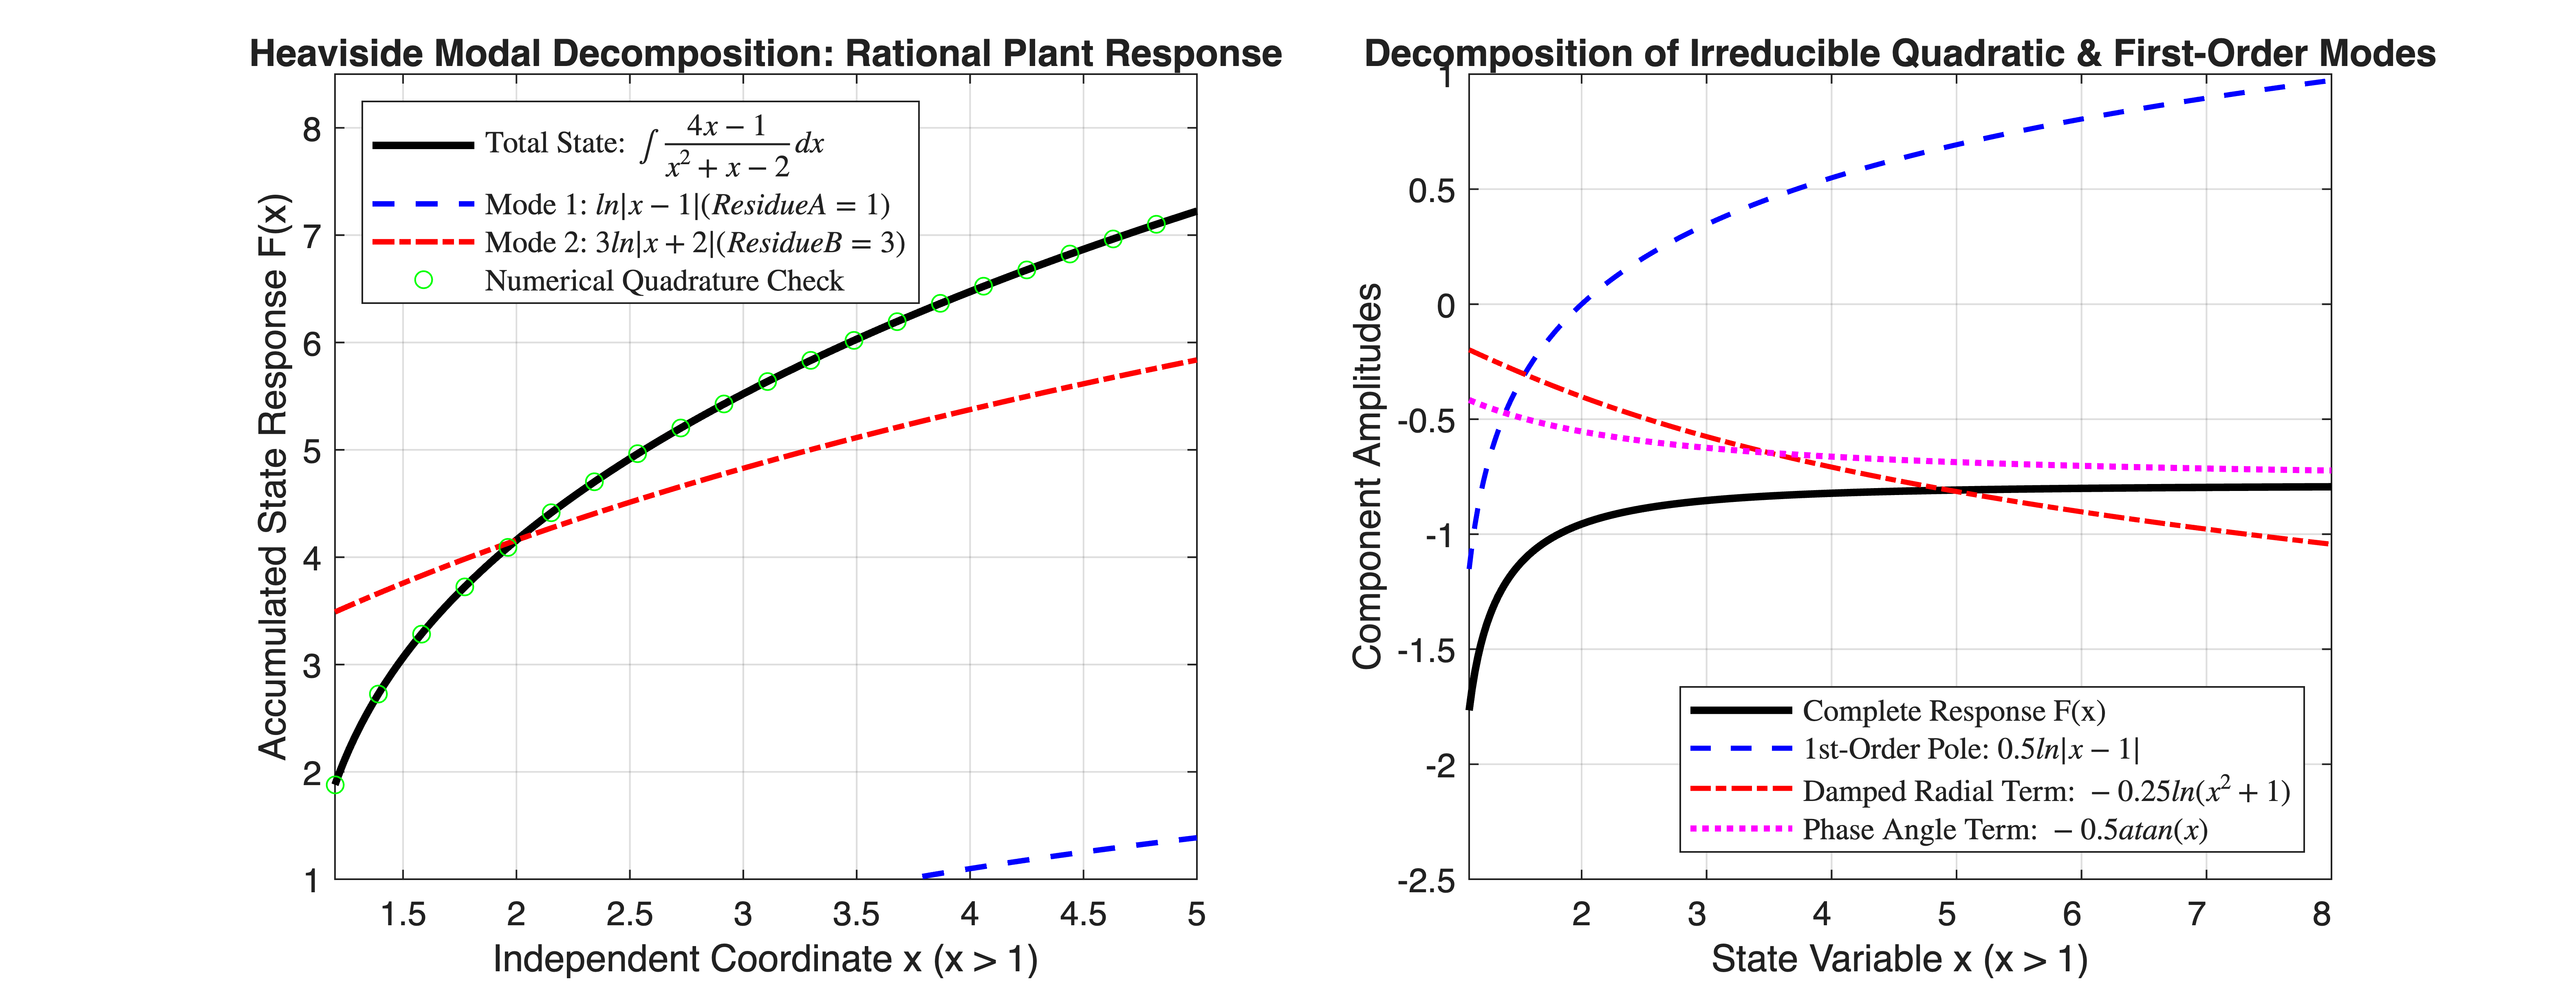

In [1]:
%% MIT 18.01 Lecture 29: Partial Fractions & Dynamic Modal Decomposition
% Mathematical Tool Application: Solves transfer function residue decomposition
% for inverse Laplace transforms, isolates discrete system physical modes,
% and evaluates exact analytical integrals of high-order rational plant dynamics.


clear; clc; close all;


%% Part 1: Partial Fraction Decomposition of f(x) = (4x - 1) / (x^2 + x - 2)
% Rational form: P(x)/Q(x) = (4x - 1) / ((x - 1)(x + 2))
% Heaviside Cover-Up: A = (4(1)-1)/(1+2) = 1; B = (4(-2)-1)/(-2-1) = 3
% Integrated Form: F(x) = ln|x - 1| + 3*ln|x + 2|
num_p = [4, -1];
den_q = [1, 1, -2]; % Roots at x = 1 and x = -2


% MATLAB Control System / Signal Processing Residue Analysis
[residues, poles, direct_terms] = residue(num_p, den_q);


% Define integration domain avoiding pole singularities (x > 1)
x_span = linspace(1.2, 5.0, 300);


f_rational = (4 * x_span - 1) ./ (x_span.^2 + x_span - 2);
F_mode1 = log(abs(x_span - 1.0));         % Due to A / (x - 1)
F_mode2 = 3.0 * log(abs(x_span + 2.0));   % Due to B / (x + 2)
F_total_analytic = F_mode1 + F_mode2;


% Numerical integration baseline via cumtrapz
F_total_numerical = cumtrapz(x_span, f_rational);
% Align constant shift at starting evaluation point
F_total_numerical = F_total_numerical + (F_total_analytic(1) - F_total_numerical(1));


figure('Color', 'w', 'Position', [100, 100, 1250, 480]);


subplot(1, 2, 1);
plot(x_span, F_total_analytic, 'k-', 'LineWidth', 2.2, 'DisplayName', 'Total State: $\int \frac{4x-1}{x^2+x-2}dx$'); hold on;
plot(x_span, F_mode1, 'b--', 'LineWidth', 1.6, 'DisplayName', 'Mode 1: $ln|x - 1| (Residue A = 1)$');
plot(x_span, F_mode2, 'r-.', 'LineWidth', 1.6, 'DisplayName', 'Mode 2: $3 ln|x + 2| (Residue B = 3)$');
plot(x_span(1:15:end), F_total_numerical(1:15:end), 'go', 'MarkerSize', 5, 'DisplayName', 'Numerical Quadrature Check');


grid on;
xlim([1.2, 5.0]); ylim([1.0, 8.5]);
xlabel('Independent Coordinate x (x > 1)');
ylabel('Accumulated State Response F(x)');
title('Heaviside Modal Decomposition: Rational Plant Response');
legend('Location', 'northwest', 'Interpreter','latex');


%% Part 2: Irreducible Quadratic Factor Decomposition: 1 / ((x^2 + 1)(x - 1))
% Lecture 29 Result: 0.5/(x - 1) - 0.25*(2x)/(x^2 + 1) - 0.5/(x^2 + 1)
% Integral: F(x) = 0.5*ln|x - 1| - 0.25*ln(x^2 + 1) - 0.5*atan(x)
subplot(1, 2, 2);
x_domain_quad = linspace(1.1, 8.0, 300);


f_complex_plant = 1.0 ./ ((x_domain_quad.^2 + 1.0) .* (x_domain_quad - 1.0));


term_first_order = 0.5 * log(abs(x_domain_quad - 1.0));
term_log_quad    = -0.25 * log(x_domain_quad.^2 + 1.0);
term_atan_phase  = -0.5 * atan(x_domain_quad);
F_quad_total     = term_first_order + term_log_quad + term_atan_phase;


plot(x_domain_quad, F_quad_total, 'k-', 'LineWidth', 2.2, 'DisplayName', 'Complete Response F(x)'); hold on;
plot(x_domain_quad, term_first_order, 'b--', 'LineWidth', 1.5, 'DisplayName', '1st-Order Pole: $0.5 ln|x - 1|$');
plot(x_domain_quad, term_log_quad,    'r-.', 'LineWidth', 1.5, 'DisplayName', 'Damped Radial Term: $-0.25 ln(x^2 + 1)$');
plot(x_domain_quad, term_atan_phase,  'm:',  'LineWidth', 1.8, 'DisplayName', 'Phase Angle Term: $-0.5 atan(x)$');


grid on;
xlim([1.1, 8.0]); ylim([-2.5, 1.0]);
xlabel('State Variable x (x > 1)');
ylabel('Component Amplitudes');
title('Decomposition of Irreducible Quadratic & First-Order Modes');
legend('Location', 'southeast', 'Interpreter','latex');